# CNN Development on a Custom Dataset: Rice Image Classification

**Course:** CVPR | **Student ID:** 23-50938-1 | **Name:** Md. Wasif Hasan

**Goal:** Train a CNN that looks at a picture of a rice grain and tells which of the 5 rice varieties it is.

## 1. Import Libraries

In [ ]:
!pip install -q torchsummary kagglehub

from torchvision import datasets
import torchvision.transforms as transforms

from torch.utils.data import Dataset, DataLoader, random_split, Subset
import torch
import torch.nn as nn
from torch.optim import Adam

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# Use GPU if we have it, because it is faster
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


## 2. Load and Explore Dataset

**Dataset:** Rice Image Dataset from Kaggle
- Link: https://www.kaggle.com/datasets/muratkokludataset/rice-image-dataset
- 75,000 colour images in total, 15,000 images for each rice variety, image size 250 x 250
- **5 classes (rice varieties grown in Turkey):** Arborio, Basmati, Ipsala, Jasmine, Karacadag
- The dataset has one folder for each class. It has no ready train/test folders, so we split it ourselves in the next section.
- The classes have exactly the same number of images, so the dataset is balanced.

In [ ]:
import os
import kagglehub

# Download the dataset from Kaggle
path = kagglehub.dataset_download("muratkokludataset/rice-image-dataset")
print("Path to dataset files:", path)

# Find the folder that has all the class folders inside
data_folder = None
for root, dirs, files in os.walk(path):
    if "Arborio" in dirs:
        data_folder = root
        break
print("Data folder:", data_folder)

Using Colab cache for faster access to the 'rice-image-dataset' dataset.
Path to dataset files: /kaggle/input/rice-image-dataset
Data folder: /kaggle/input/rice-image-dataset/Rice_Image_Dataset


In [ ]:
# Load all images. Every class folder becomes one class.
full_data = datasets.ImageFolder(data_folder)

print("Total images:", len(full_data))
print("Number of classes:", len(full_data.classes))
print()

# Show how many images each class has
counts = np.bincount(full_data.targets)
for name, c in zip(full_data.classes, counts):
    print(f"{name:15s} {c}")

Total images: 75000
Number of classes: 5

Arborio         15000
Basmati         15000
Ipsala          15000
Jasmine         15000
Karacadag       15000


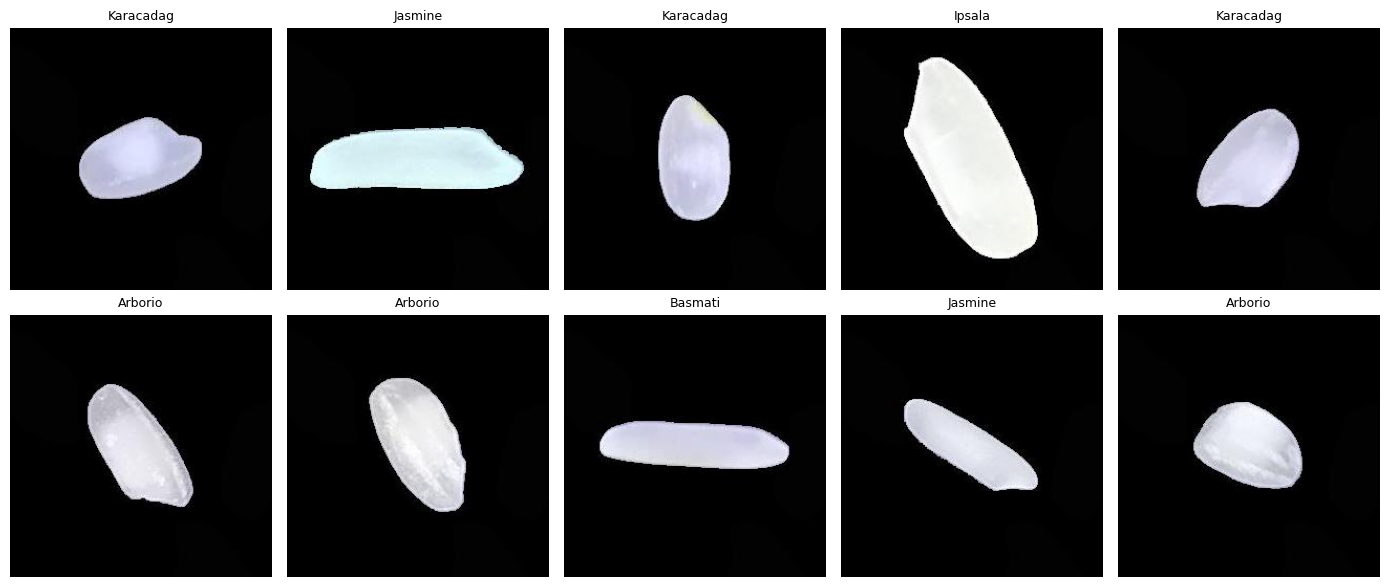

In [ ]:
# Show some random images with their class names
ROWS, COLS = 2, 5
fig, axes = plt.subplots(ROWS, COLS, figsize=(14, 6))
for ax in axes.flat:
    i = np.random.randint(len(full_data))
    img, label = full_data[i]
    ax.imshow(img)
    ax.set_title(full_data.classes[label], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

**What we see:** Every grain is photographed alone on a black background. The classes have the same number of images. Some varieties look alike (for example Basmati and Jasmine are both long white grains), so the model may mix them up a little.

## 3. Data Preprocessing and Augmentation

- **Images per class:** The full dataset has 75,000 images, which takes a long time to train in Colab. We use a random 5,000 images from each class (25,000 images in total). Because every class has the same number of images, the data stays balanced. To use all the images, set `images_per_class = 15000`.
- **Resize to 64 x 64:** Small images train faster, and the CNN needs all images to be the same size.
- **ToTensor:** Changes the image to numbers between 0 and 1.
- **Augmentation (train data only):** Random flip, small rotation and small colour change. This makes new versions of the same picture, so the model does not just remember the training pictures.
- **Validation and test data:** No augmentation, so the score is fair.
- **Split:** 70% train, 20% validation, 10% test (random split).

In [ ]:
size = 64

train_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor()
])

val_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor()
])

# Same folder loaded two times: one with augmentation, one without
aug_full = datasets.ImageFolder(data_folder, transform=train_transform)
plain_full = datasets.ImageFolder(data_folder, transform=val_transform)

# Pick the same number of random images from every class
images_per_class = 5000
targets = np.array(aug_full.targets)
rng = np.random.RandomState(42)
chosen = []
for c in range(len(aug_full.classes)):
    class_idx = np.where(targets == c)[0]
    rng.shuffle(class_idx)
    chosen.extend(class_idx[:images_per_class].tolist())

aug_data = Subset(aug_full, chosen)
plain_data = Subset(plain_full, chosen)

# Split sizes: 70% train, 20% validation, 10% test
total = len(aug_data)
train_size = int(0.7 * total)
val_size = int(0.2 * total)
test_size = total - train_size - val_size

# Same seed gives the same split for both copies, so no image is in two sets
train_data, _, _ = random_split(aug_data, [train_size, val_size, test_size],
                                generator=torch.Generator().manual_seed(42))
_, val_data, test_data = random_split(plain_data, [train_size, val_size, test_size],
                                      generator=torch.Generator().manual_seed(42))

class_names = aug_full.classes
num_classes = len(class_names)

In [ ]:
print('Dataset Summary')
print('Total images used: ', total)
print('Train Data: ', len(train_data))
print('Validation Data: ', len(val_data))
print('Test Data: ', len(test_data))
print('Classes and Indices: ', aug_full.class_to_idx)

Dataset Summary
Total images used:  25000
Train Data:  17500
Validation Data:  5000
Test Data:  2500
Classes and Indices:  {'Arborio': 0, 'Basmati': 1, 'Ipsala': 2, 'Jasmine': 3, 'Karacadag': 4}


In [ ]:
# Hyperparameters
batch_size = 32
learning_rate = 1e-3
epoch_number = 20

In [ ]:
trn_dl = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2)
val_dl = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=2)
test_dl = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2)

### Hyperparameters and why we use them

| Hyperparameter | Value | Reason |
|---|---|---|
| Image size | 64 x 64 | Fast training, still shows the shape and colour of the grain |
| Images per class | 5,000 | Balanced data and faster training than using all 15,000 |
| Batch size | 32 | Advised by our faculty. Small batches update the weights more often and use less memory |
| Optimizer | Adam | It changes the learning speed by itself, so it learns fast |
| Learning rate | 0.001 | The normal safe value for Adam |
| Loss function | Cross-Entropy | The standard loss for many classes |
| Epochs | 20 | Enough to learn, not too long |
| Split | 70 / 20 / 10 | Most data to learn, a bigger validation set to choose the model, and a small test set for the final check |

## 4. Define CNN Architecture

**Feature extraction (finds patterns):**
- `Conv2d(3, 64)` then `Conv2d(64, 64)` then MaxPool
- `Conv2d(64, 128)` then `Conv2d(128, 128)` then MaxPool
- The second conv in each block keeps the same number of channels (64 to 64, 128 to 128) so it can improve the patterns found by the first one.
- ReLU after each conv layer lets the network learn non-straight-line patterns. MaxPool makes the image smaller.

**Classifier (makes the decision):** Flatten, then Linear layers. The last layer has 5 outputs, one for each rice variety.

**We test 2 different Linear layer designs and see which one is better:**

| Model | Linear layers |
|---|---|
| A | 256 -> 5 |
| B | 512 -> 256 -> 5 |

After the conv part, the image size is 13 x 13 with 128 channels, so the flatten size is 128 x 13 x 13.

In [ ]:
def get_model(choice):
    if choice == "A":
        model = nn.Sequential(
            # Feature Extraction
            nn.Conv2d(3, 64, kernel_size=3),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Classifier
            nn.Flatten(),
            nn.Linear(128*13*13, 256),
            nn.ReLU(),
            nn.Linear(256, 5)
        ).to(device)

    else:
        model = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Flatten(),
            nn.Linear(128*13*13, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, 5)
        ).to(device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer

In [ ]:
# Detailed summary of the architecture (Model A)
from torchsummary import summary
model, loss_fn, optimizer = get_model("A")
summary(model, input_size=(3, size, size));

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 62, 62]           1,792
              ReLU-2           [-1, 64, 62, 62]               0
            Conv2d-3           [-1, 64, 60, 60]          36,928
              ReLU-4           [-1, 64, 60, 60]               0
         MaxPool2d-5           [-1, 64, 30, 30]               0
            Conv2d-6          [-1, 128, 28, 28]          73,856
              ReLU-7          [-1, 128, 28, 28]               0
            Conv2d-8          [-1, 128, 26, 26]         147,584
              ReLU-9          [-1, 128, 26, 26]               0
        MaxPool2d-10          [-1, 128, 13, 13]               0
          Flatten-11                [-1, 21632]               0
           Linear-12                  [-1, 256]       5,538,048
             ReLU-13                  [-1, 256]               0
           Linear-14                   

In [ ]:
# Detailed summary of the architecture (Model B)
model, loss_fn, optimizer = get_model("B")
summary(model, input_size=(3, size, size));

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 62, 62]           1,792
              ReLU-2           [-1, 64, 62, 62]               0
            Conv2d-3           [-1, 64, 60, 60]          36,928
              ReLU-4           [-1, 64, 60, 60]               0
         MaxPool2d-5           [-1, 64, 30, 30]               0
            Conv2d-6          [-1, 128, 28, 28]          73,856
              ReLU-7          [-1, 128, 28, 28]               0
            Conv2d-8          [-1, 128, 26, 26]         147,584
              ReLU-9          [-1, 128, 26, 26]               0
        MaxPool2d-10          [-1, 128, 13, 13]               0
          Flatten-11                [-1, 21632]               0
           Linear-12                  [-1, 512]      11,076,096
             ReLU-13                  [-1, 512]               0
           Linear-14                  [

## 5. Training Loop with Validation

In [ ]:
def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()
    epoch_losses, epoch_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        prediction = model(x)
        batch_loss = loss_fn(prediction, y)
        batch_loss.backward()
        optimizer.step()

        epoch_losses.append(batch_loss.item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        epoch_accuracies.extend(is_correct)
    return np.mean(epoch_losses), np.mean(epoch_accuracies)

@torch.no_grad()
def validation(data_loader, model, loss_fn):
    model.eval()
    val_losses, val_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)
        prediction = model(x)
        val_losses.append(loss_fn(prediction, y).item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        val_accuracies.extend(is_correct)
    return np.mean(val_losses), np.mean(val_accuracies)

In [ ]:
## Training Loop: train Model A and Model B one by one ##
all_models = {}
all_history = {}

for choice in ["A", "B"]:
    print("=" * 60)
    print("Training Model", choice)
    print("=" * 60)

    torch.manual_seed(42)
    model, loss_fn, optimizer = get_model(choice)

    train_losses, train_accuracies = [], []
    val_losses, val_accuracies = [], []

    for epoch in range(epoch_number):
        epoch_loss, epoch_accuracy = train_one_epoch(trn_dl, model, loss_fn, optimizer)
        train_losses.append(epoch_loss)
        train_accuracies.append(epoch_accuracy)

        v_loss, v_acc = validation(val_dl, model, loss_fn)
        val_losses.append(v_loss)
        val_accuracies.append(v_acc)

        print(f"Epoch [{epoch + 1}/{epoch_number}]"
              f" | Train Loss: {epoch_loss:.4f} | Train Accuracy: {epoch_accuracy*100:.2f}%"
              f" | Val Loss: {v_loss:.4f} | Val Accuracy: {v_acc*100:.2f}%")

    all_models[choice] = model
    all_history[choice] = (train_losses, train_accuracies, val_losses, val_accuracies)

Training Model A
Epoch [1/20] | Train Loss: 0.2134 | Train Accuracy: 92.07% | Val Loss: 0.0829 | Val Accuracy: 96.88%
Epoch [2/20] | Train Loss: 0.1154 | Train Accuracy: 96.11% | Val Loss: 0.0931 | Val Accuracy: 96.70%
Epoch [3/20] | Train Loss: 0.0972 | Train Accuracy: 96.78% | Val Loss: 0.0579 | Val Accuracy: 97.90%
Epoch [4/20] | Train Loss: 0.0889 | Train Accuracy: 96.90% | Val Loss: 0.0660 | Val Accuracy: 97.52%
Epoch [5/20] | Train Loss: 0.0733 | Train Accuracy: 97.68% | Val Loss: 0.0612 | Val Accuracy: 97.82%
Epoch [6/20] | Train Loss: 0.0639 | Train Accuracy: 97.83% | Val Loss: 0.0342 | Val Accuracy: 98.98%
Epoch [7/20] | Train Loss: 0.0577 | Train Accuracy: 98.11% | Val Loss: 0.0284 | Val Accuracy: 99.00%
Epoch [8/20] | Train Loss: 0.0483 | Train Accuracy: 98.47% | Val Loss: 0.0236 | Val Accuracy: 99.10%
Epoch [9/20] | Train Loss: 0.0497 | Train Accuracy: 98.34% | Val Loss: 0.0300 | Val Accuracy: 98.86%
Epoch [10/20] | Train Loss: 0.0485 | Train Accuracy: 98.41% | Val Loss: 0.

## 6. Evaluate Model on Test Set
First we compare the 2 models using the **validation** accuracy of the last epoch. We choose the best one by validation (not by test), and then we use the test set only one time.

In [ ]:
# Compare the 2 models
for choice in ["A", "B"]:
    tl, ta, vl, va = all_history[choice]
    print(f"Model {choice} | Train Acc: {ta[-1]*100:.2f}% | Val Acc: {va[-1]*100:.2f}% | Val Loss: {vl[-1]:.4f}")

best_choice = max(all_history, key=lambda k: all_history[k][3][-1])
print("\nBest model:", best_choice)

Model A | Train Acc: 99.02% | Val Acc: 99.08% | Val Loss: 0.0239
Model B | Train Acc: 98.70% | Val Acc: 99.06% | Val Loss: 0.0242

Best model: A


In [ ]:
# Test the best model on the test set
model = all_models[best_choice]
loss_fn = nn.CrossEntropyLoss()

test_loss, test_acc = validation(test_dl, model, loss_fn)
print(f'Test Loss : {test_loss:0.2f} , Test Accuracy: {test_acc*100:0.2f}%')

Test Loss : 0.03 , Test Accuracy: 99.04%


In [ ]:
# Test accuracy of both models (just to compare)
for choice in ["A", "B"]:
    t_loss, t_acc = validation(test_dl, all_models[choice], loss_fn)
    print(f'Model {choice} | Test Loss : {t_loss:0.2f} , Test Accuracy: {t_acc*100:0.2f}%')

Model A | Test Loss : 0.03 , Test Accuracy: 99.04%
Model B | Test Loss : 0.03 , Test Accuracy: 99.16%


## 7. Visualizations (Loss and Accuracy Curves)
- Loss should go down and accuracy should go up.
- If validation loss goes up while training loss goes down, the model is overfitting.

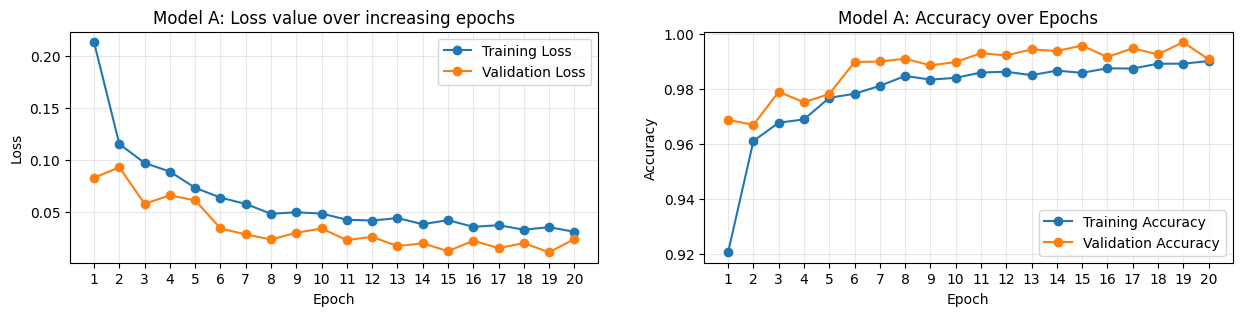

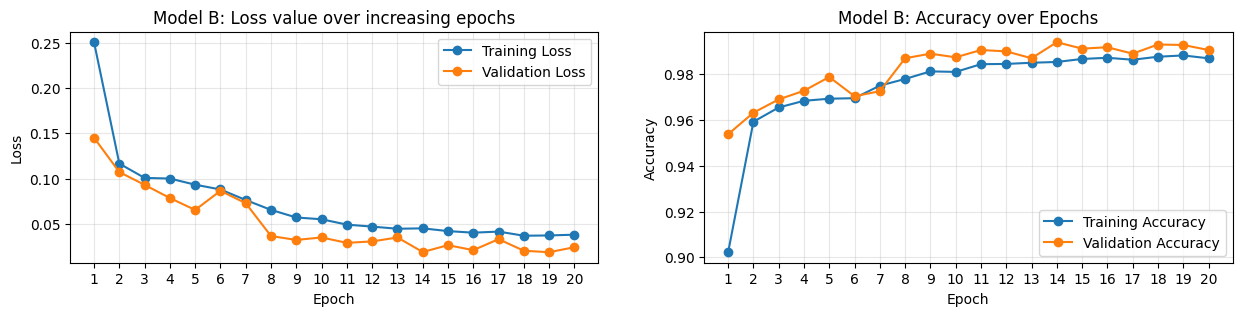

In [ ]:
epochs = np.arange(epoch_number) + 1

for choice in ["A", "B"]:
    train_losses, train_accuracies, val_losses, val_accuracies = all_history[choice]

    plt.figure(figsize=(15, 3))
    plt.subplot(121)
    plt.title(f"Model {choice}: Loss value over increasing epochs")
    plt.plot(epochs, train_losses, marker='o', label="Training Loss")
    plt.plot(epochs, val_losses, marker='o', label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.xticks(epochs)
    plt.legend()
    plt.grid(alpha=0.3)

    plt.subplot(122)
    plt.title(f"Model {choice}: Accuracy over Epochs")
    plt.plot(epochs, train_accuracies, marker='o', label="Training Accuracy")
    plt.plot(epochs, val_accuracies, marker='o', label="Validation Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.xticks(epochs)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

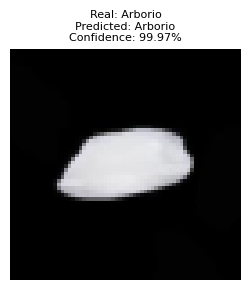

In [ ]:
# Predict one test image with the best model
model.eval()
test_img, label = test_data[2]
img = test_img.view(-1, 3, size, size).to(device)

output = model(img)
pred = torch.softmax(output, dim=-1)
confidence, index = pred.max(-1)

plt.figure(figsize=(3, 3))
plt.imshow(test_img.view(3, size, size).permute(1, 2, 0))
plt.title(f'Real: {class_names[label]}\nPredicted: {class_names[index]}\nConfidence: {confidence.item()*100:0.2f}%', fontsize=8)
plt.axis("off")
plt.show()

## 8. Analysis and Discussion of Results

The CNN models performed very well in classifying the five rice varieties: Arborio, Basmati, Ipsala, Jasmine, and Karacadag.
We trained two different models (Model A and Model B) for 20 epochs using 25,000 images. Both models achieved high training and validation accuracy.
Model Comparison:
Model A achieved 99.02% training accuracy and 99.08% validation accuracy.
Model B achieved 98.70% training accuracy and 99.06% validation accuracy.
Based on the final validation accuracy, Model A was selected as the best model.
Test Results:
Model A achieved 99.04% test accuracy with a test loss of approximately 0.03.
Model B achieved 99.16% test accuracy with a test loss of approximately 0.03.
Although Model B achieved slightly higher test accuracy, Model A was selected because it had the higher final validation accuracy. This follows our model selection approach, where the validation set is used to select the best model.
From the training graphs, we can observe that the training loss generally decreased while the accuracy increased. The validation loss also remained low, and validation accuracy stayed around 99%. This indicates that the models learned the important features of the rice images and performed consistently on unseen data.
Model A has fewer parameters (5,799,493) than Model B (11,468,869), making it a simpler and smaller model while maintaining excellent performance.
Overall, the results show that CNNs are highly effective for classifying rice varieties based on image features such as shape, colour, and texture.

## 9. Conclusions and Future Work

In this project, we successfully developed a Convolutional Neural Network (CNN) to classify five different varieties of rice using image data. We used image preprocessing, data augmentation, convolutional layers, ReLU activation, and MaxPooling to build and train the models.
We experimented with two different CNN architectures and compared their performance. Model A was selected based on its validation accuracy of 99.08%. It achieved 99.04% accuracy on the test dataset, showing that it can classify rice varieties with very high accuracy.
We also saved the trained model weights and loaded them into a new model. The loaded model achieved the same test accuracy of 99.04%, confirming that the model was saved and restored successfully.
Future Work:
Use the complete dataset of 75,000 images to train the model.
Experiment with deeper CNN architectures to improve performance.
Apply transfer learning using pretrained models such as ResNet or MobileNet.
Test the model using real-world rice images with different lighting conditions and backgrounds.
Develop a simple web or mobile application where users can upload a rice image and get its predicted variety.
Use confusion matrices to understand which rice varieties are more likely to be misclassified.
In conclusion, this project demonstrates that CNN-based image classification can achieve excellent results in identifying different rice varieties. The selected Model A provides a good balance between model complexity and classification performance.

## Save and Load the Model Weights
We save only the weights (`state_dict`). If the file is bigger than 20 MB, do not upload it to GitHub. Keep a local copy.

In [ ]:
# Save the weights of the best model
save_path = "cnn_rice_best_model.pth"
torch.save(model.state_dict(), save_path)

file_size_mb = os.path.getsize(save_path) / 1024 / 1024
print(f"Saved to {save_path} | File size: {file_size_mb:.1f} MB")
if file_size_mb > 20:
    print("File is bigger than 20 MB: keep it on your computer, do not upload to GitHub.")

Saved to cnn_rice_best_model.pth | File size: 22.1 MB
File is bigger than 20 MB: keep it on your computer, do not upload to GitHub.


In [ ]:
# Make a new empty model with the same design, then put the saved weights inside it
saved_model = get_model(best_choice)[0]
saved_model.load_state_dict(torch.load(save_path, map_location=device))
saved_model.eval()
summary(saved_model, (3, size, size))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 62, 62]           1,792
              ReLU-2           [-1, 64, 62, 62]               0
            Conv2d-3           [-1, 64, 60, 60]          36,928
              ReLU-4           [-1, 64, 60, 60]               0
         MaxPool2d-5           [-1, 64, 30, 30]               0
            Conv2d-6          [-1, 128, 28, 28]          73,856
              ReLU-7          [-1, 128, 28, 28]               0
            Conv2d-8          [-1, 128, 26, 26]         147,584
              ReLU-9          [-1, 128, 26, 26]               0
        MaxPool2d-10          [-1, 128, 13, 13]               0
          Flatten-11                [-1, 21632]               0
           Linear-12                  [-1, 256]       5,538,048
             ReLU-13                  [-1, 256]               0
           Linear-14                   

In [ ]:
# Check the loaded model on the test set. The result should be the same as before.
l_loss, l_acc = validation(test_dl, saved_model, nn.CrossEntropyLoss())
print(f'Loaded model test accuracy: {l_acc*100:.2f}%')

Loaded model test accuracy: 99.04%


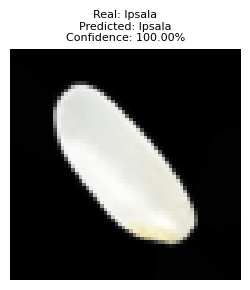

In [ ]:
# Pick a random test image and predict it with the loaded model
test_img, label = test_data[np.random.randint(0, len(test_data))]
img = test_img.view(-1, 3, size, size).to(device)

output = saved_model(img)
pred = torch.softmax(output, dim=-1)
confidence, index = pred.max(-1)

plt.figure(figsize=(3, 3))
plt.imshow(test_img.permute(1, 2, 0))
plt.title(f"Real: {class_names[label]}\nPredicted: {class_names[index]}\nConfidence: {confidence.item()*100:0.2f}%", fontsize=8)
plt.axis("off")
plt.show()